In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

from pathlib import Path
from pyproj import Transformer

random.seed(42)

import sys
sys.path.append("../src")

from config import (
    GRID_SIZE, INTERVAL_MINUTES,
    CENTER_ZIP, N_ZIPS, MIN_ZIP_INCIDENTS,
    BIN_METHOD, TRIM_PCT, N_YEARS, DROP_MIDNIGHT,
    RAW_PATH, CENSUS_PATH, PROCESSED_DIR,
    DAILY_CRIMES, RATE_FLOOR_FRACTION,
)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
NON_PATROL_OFFENSES = [
    "Counterfeiting/Forgery", 
    "Credit Card/Automatic Teller Fraud", 
    "Embezzlement", 
    "False Pretenses/Swindle/Confidence Game", 
    "Identity Theft", 
    "Impersonation", 
    "Hacking/Computer Invasion", 
    "Welfare Fraud", 
    "Betting/Wagering", 
    "Gambling Equipment Violations", 
    "Operating/Promoting/Assisting Gambling", 
    "Pornography/Obscene Material", 
    "Bribery"
]

## Loading raw dataset

In [4]:
crime_raw = pd.read_csv(RAW_PATH)

KEEP_COLUMNS = [
    "Incident UID",
    "Incident Date",
    "Zip Code",
    "Census Tract",
    "CIBRS Offense Description"
]

crime_clean = crime_raw[KEEP_COLUMNS].copy()
print("original # rows:", len(crime_raw))

print("columns:", crime_clean.columns.tolist())
display(crime_clean.head())

original # rows: 806935
columns: ['Incident UID', 'Incident Date', 'Zip Code', 'Census Tract', 'CIBRS Offense Description']


,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description
0,604311,2021 Jan 01 01:25:00 AM,92115.0,NaN,Destruction/Damage/Vandalism of Property
1,605986,2021 Jan 01 08:40:00 AM,92101.0,NaN,Impersonation
2,773968,2021 Jan 01 12:30:00 PM,NaN,NaN,Aggravated Assault
3,687369,2021 Jan 03 01:00:00 AM,92019.0,NaN,All Other Larceny
4,1072215,2021 Jan 03 04:37:00 PM,NaN,NaN,Simple Assault


## Cleaning cols/rows

In [5]:
#convert dats to datetime 
crime_clean["Incident Date"] = pd.to_datetime(
    crime_clean["Incident Date"],
    format="%Y %b %d %I:%M:%S %p",
    errors="coerce"
)

#remove invalid ids/ dates
crime_clean = crime_clean.dropna(
    subset=["Incident UID", "Incident Date"]
).copy()

crime_clean["Zip Code"] = pd.to_numeric(
    crime_clean["Zip Code"],
    errors="coerce"
).astype("Int64")

crime_clean["Census Tract"] = pd.to_numeric(
    crime_clean["Census Tract"],
    errors="coerce"
)

#remove rows without ZIP or census tract
crime_clean = crime_clean.dropna(
    subset=["Zip Code", "Census Tract"]
).copy()

print("cleaned zips, tract #rows :", len(crime_clean))
print("unique incidents:", crime_clean["Incident UID"].nunique())
print("unique zips:", crime_clean["Zip Code"].nunique())
print("unique tracts:", crime_clean["Census Tract"].nunique())

cleaned zips, tract #rows : 767880
unique incidents: 606150
unique zips: 112
unique tracts: 736


In [6]:
crime_clean = crime_clean[
    ~crime_clean["CIBRS Offense Description"].isin(
        NON_PATROL_OFFENSES
    )
].copy()

print("cleaned offenses #rows :", len(crime_clean))

print(
    "# offense types:",
    crime_clean["CIBRS Offense Description"].nunique()
)

cleaned offenses #rows : 721145
# offense types: 35


In [7]:
#time features 
crime_clean["Year"] = crime_clean["Incident Date"].dt.year
crime_clean["Month"] = crime_clean["Incident Date"].dt.month
crime_clean["Day"] = crime_clean["Incident Date"].dt.day
crime_clean["Hour"] = crime_clean["Incident Date"].dt.hour
crime_clean["Minute"] = crime_clean["Incident Date"].dt.minute

#divide into our intervals/steps 
crime_clean["Time Step"] = (
    crime_clean["Hour"] * 60
    + crime_clean["Minute"]
) // INTERVAL_MINUTES

display(crime_clean.head())

,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description,Year,Month,Day,Hour,Minute,Time Step
5,608584,2021-01-03 19:30:00,92110,68.02,Motor Vehicle Theft,2021,1,3,19,30,78
6,1002702,2021-01-03 20:00:00,92102,41.02,Motor Vehicle Theft,2021,1,3,20,0,80
10,642766,2021-01-05 16:00:00,91910,134.09,Motor Vehicle Theft,2021,1,5,16,0,64
11,548636,2021-01-06 22:39:00,92025,203.13,Motor Vehicle Theft,2021,1,6,22,39,90
14,1071423,2021-01-07 14:40:00,92110,66.00,Robbery,2021,1,7,14,40,58


In [8]:
# 1) Date range and keep the last N_YEARS complete calendar years
print("date range:", crime_clean["Incident Date"].min(), "to", crime_clean["Incident Date"].max())

last_date = crime_clean["Incident Date"].max()
last_full_year = last_date.year if (last_date.month == 12 and last_date.day >= 28) else last_date.year - 1
first_year = last_full_year - N_YEARS + 1

crime_clean = crime_clean[crime_clean["Year"].between(first_year, last_full_year)].copy()

N_DAYS = (pd.Timestamp(last_full_year, 12, 31) - pd.Timestamp(first_year, 1, 1)).days + 1
print(f"keeping {first_year}-{last_full_year}: {len(crime_clean)} rows, {N_DAYS} days")

# 2) Midnight check: are there too many records at exactly 00:00:00?
is_midnight = crime_clean["Incident Date"].dt.time == pd.Timestamp("00:00:00").time()
print("share at exactly 00:00:00:", round(is_midnight.mean() * 100, 2), "% (expected about 0.07%)")
print(crime_clean["Hour"].value_counts().sort_index())

if DROP_MIDNIGHT:
    crime_clean = crime_clean[~is_midnight].copy()
    print("after dropping midnight rows:", len(crime_clean))

date range: 2021-01-01 00:00:01 to 2026-11-07 23:38:59
keeping 2023-2025: 354837 rows, 1096 days
share at exactly 00:00:00: 0.01 % (expected about 0.07%)
Hour
0     15265
1     11712
2      9998
3      8142
4      6404
5      5603
6      7193
7     10403
8     14100
9     13246
10    14978
11    14689
12    20351
13    15072
14    16514
15    18266
16    19690
17    20767
18    20690
19    19498
20    20057
21    18568
22    18136
23    15495
Name: count, dtype: int64


## Geographic

- Each ZIP’s center is the average position of its incidents’ tracts.
- It keeps the ZIPs with at least 500 incidents, then the 40 closest to 92101.
- The result is one compact area instead of 40 scattered ZIPs.
- Cell 11’s old print statements now live here.

In [9]:
# --- GEOID: matches a census tract number like 68.02 to the Census file's ID ---
def tract_to_geoid(value):
    integer_part, decimal_part = f"{float(value):.2f}".split(".")
    return "06073" + integer_part.zfill(4) + decimal_part

geoid_lookup = {t: tract_to_geoid(t) for t in crime_clean["Census Tract"].drop_duplicates()}
crime_clean["GEOID"] = crime_clean["Census Tract"].map(geoid_lookup)

# --- load tract center points for the whole county ---
census_raw = pd.read_csv(CENSUS_PATH, sep="|", dtype={"GEOID": str})
tract_all = census_raw[census_raw["GEOID"].str.startswith("06073")][["GEOID", "INTPTLAT", "INTPTLONG"]].copy()
tract_all = tract_all.rename(columns={"INTPTLAT": "lat", "INTPTLONG": "lon"})

# --- convert lat/lon (degrees) to x/y (meters) so distances are real ---
transformer = Transformer.from_crs("EPSG:4326", "EPSG:32611", always_xy=True)
tract_all["x"], tract_all["y"] = transformer.transform(
    tract_all["lon"].astype(float).values,
    tract_all["lat"].astype(float).values
)

# --- attach each tract's x/y to every incident ---
crime_clean = crime_clean.merge(
    tract_all[["GEOID", "lat", "lon", "x", "y"]],
    on="GEOID", how="left", validate="many_to_one"
)
print("incidents with no tract coordinates:", crime_clean["x"].isna().sum())
crime_clean = crime_clean.dropna(subset=["x", "y"]).copy()
print("rows now:", len(crime_clean))

incidents with no tract coordinates: 0
rows now: 354837


In [10]:
# one row per ZIP: how many incidents, and the average x/y of its incidents
zip_stats = (
    crime_clean.groupby("Zip Code")
    .agg(incidents=("Incident UID", "size"), zip_x=("x", "mean"), zip_y=("y", "mean"))
    .reset_index()
)
zip_stats = zip_stats[zip_stats["incidents"] >= MIN_ZIP_INCIDENTS].copy()

# distance (km) from each ZIP to the center ZIP
center = zip_stats[zip_stats["Zip Code"] == CENTER_ZIP].iloc[0]
zip_stats["dist_km"] = np.hypot(zip_stats["zip_x"] - center["zip_x"],
                                zip_stats["zip_y"] - center["zip_y"]) / 1000

nearest = zip_stats.sort_values("dist_km").head(N_ZIPS)
all_selected_zips = nearest["Zip Code"].astype(int).tolist()

print("selected zips:", all_selected_zips)
print("farthest selected ZIP is", round(nearest["dist_km"].max(), 1), "km from center")

crime_sampled = crime_clean[crime_clean["Zip Code"].isin(all_selected_zips)].copy()
print("row#:", len(crime_sampled))
print("unique zips:", crime_sampled["Zip Code"].nunique())
print("unique tracts:", crime_sampled["GEOID"].nunique())

selected zips: [92101, 92103, 92113, 92102, 92104, 92116, 92110, 92108, 92106, 92105, 91950, 92107, 92115, 92114, 92111, 92123, 92120, 92109, 92139, 91910, 91945, 92117, 92124, 91902, 91941, 91942, 91911, 91977, 91932, 92119, 92122, 92037, 92173, 91913, 91978, 91914, 92121, 92020, 92154, 92126]
farthest selected ZIP is 21.7 km from center
row#: 232008
unique zips: 40
unique tracts: 427


## Geospatial mapping

In [11]:
tract_coordinates = (
    crime_sampled[["GEOID", "lat", "lon", "x", "y"]]
    .drop_duplicates("GEOID").copy()
)

def to_bins(values, method):
    if method == "rank":
        # equal-count bins: each of the 20 bins holds the same number of tracts
        ranks = values.rank(method="first")
        bins = np.floor((ranks - 1) / len(values) * GRID_SIZE)
    else:
        # equal-width bins between the 2nd and 98th percentile
        lo, hi = np.percentile(values, [TRIM_PCT, 100 - TRIM_PCT])
        bins = np.floor((values - lo) / (hi - lo) * GRID_SIZE)
    return bins.clip(0, GRID_SIZE - 1).astype(int)

tract_coordinates["grid_x"] = to_bins(tract_coordinates["x"], BIN_METHOD)                  # west -> east
tract_coordinates["grid_y"] = GRID_SIZE - 1 - to_bins(tract_coordinates["y"], BIN_METHOD)  # north = row 0

print("tracts:", len(tract_coordinates))
print("occupied grid cells:", tract_coordinates[["grid_x", "grid_y"]].drop_duplicates().shape[0])

tracts: 427
occupied grid cells: 256


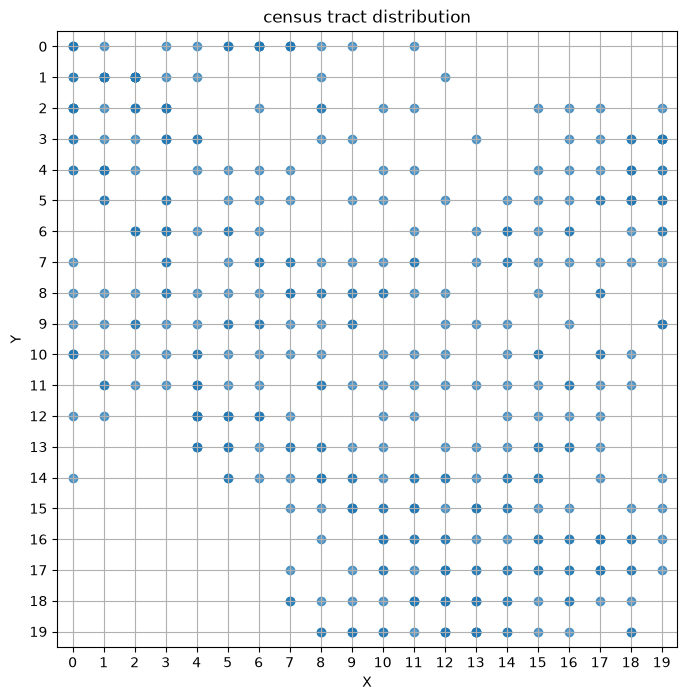

In [12]:
#checking distribution
plt.figure(figsize=(8, 8))

plt.scatter(
    tract_coordinates["grid_x"],
    tract_coordinates["grid_y"],
    alpha=0.7
)

plt.xlim(-0.5, GRID_SIZE - 0.5)
plt.ylim(GRID_SIZE - 0.5, -0.5)

plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))

plt.grid(True)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("census tract distribution")

plt.show()

In [13]:
crime_geocoded = crime_sampled.merge(
    tract_coordinates[["GEOID", "grid_x", "grid_y"]],
    on="GEOID",
    how="left",
    validate="many_to_one"
)

print("missing grid coords:", crime_geocoded["grid_x"].isna().sum())

display(crime_geocoded.head())

missing grid coords: 0


,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description,Year,Month,Day,Hour,Minute,Time Step,GEOID,lat,lon,x,y,grid_x,grid_y
0,1984131,2023-01-21 02:00:00,91910,123.03,Motor Vehicle Theft,2023,1,21,2,0,8,06073012303,32.651439,-117.072425,493207.880118,3.612649e+06,12,16
1,1628522,2023-03-08 16:00:09,92173,101.06,Motor Vehicle Theft,2023,3,8,16,0,64,06073010106,32.571812,-117.072345,493209.338371,3.603822e+06,12,19
2,1916622,2023-05-06 20:50:00,91910,124.02,Motor Vehicle Theft,2023,5,6,20,50,83,06073012402,32.643059,-117.087896,491756.199701,3.611721e+06,10,16
3,1707459,2023-06-01 15:00:00,92154,100.17,Motor Vehicle Theft,2023,6,1,15,0,60,06073010017,32.574693,-117.029346,497245.570160,3.604139e+06,15,19
4,1753157,2023-06-05 21:10:59,92101,53.01,Robbery,2023,6,5,21,10,84,06073005301,32.715696,-117.158805,485117.695366,3.619781e+06,4,12


occupied cells: 256 of 400
largest cell share: 4.4 %
top 10 cells share: 21.8 %


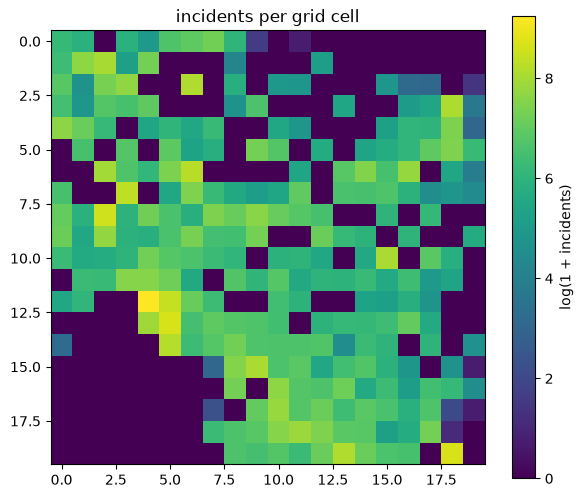

In [14]:
check = crime_sampled.merge(tract_coordinates[["GEOID", "grid_x", "grid_y"]], on="GEOID")
cell_counts = check.groupby(["grid_y", "grid_x"]).size()

print("occupied cells:", len(cell_counts), "of", GRID_SIZE * GRID_SIZE)
print("largest cell share:", round(cell_counts.max() / cell_counts.sum() * 100, 1), "%")
print("top 10 cells share:", round(cell_counts.nlargest(10).sum() / cell_counts.sum() * 100, 1), "%")

grid = np.zeros((GRID_SIZE, GRID_SIZE))
for (r, c), n in cell_counts.items():
    grid[r, c] = n

plt.figure(figsize=(7, 6))
plt.imshow(np.log1p(grid), cmap="viridis")
plt.colorbar(label="log(1 + incidents)")
plt.title("incidents per grid cell")
plt.show()

## Incident aggregation

In [15]:
exact_duplicates = crime_geocoded.duplicated().sum()
print("exact dupes#:", exact_duplicates)
crime_geocoded = crime_geocoded.drop_duplicates().copy()
print("after deduping #:", len(crime_geocoded))

exact dupes#: 25081
after deduping #: 206927


In [16]:
uid_summary = (
    crime_geocoded.groupby("Incident UID")
    .agg(
        row_count=("Incident UID", "size"),
        distinct_offenses=("CIBRS Offense Description", "nunique"),
        offense_descriptions=(
            "CIBRS Offense Description",
            lambda x: list(x.dropna().unique())
        )
    )
    .reset_index()
)

repeated_uids = uid_summary[
    uid_summary["row_count"] > 1
]

print("unique incidents:", len(uid_summary))
print("incidents with multiple rows:", len(repeated_uids))

display(repeated_uids.head(20))

unique incidents: 182419
incidents with multiple rows: 21468


,Incident UID,row_count,distinct_offenses,offense_descriptions
4,1520156,2,2,"[Theft From Building, Burglary/Breaking & Ente..."
40,1522466,2,2,"[Destruction/Damage/Vandalism of Property, The..."
41,1522476,2,2,"[Theft From Motor Vehicle, Destruction/Damage/..."
106,1525483,2,2,"[Simple Assault, Kidnaping/Abduction]"
111,1525651,2,2,"[Simple Assault, Kidnaping/Abduction]"
172,1527398,2,2,"[Destruction/Damage/Vandalism of Property, Agg..."
226,1528617,2,2,"[Destruction/Damage/Vandalism of Property, The..."
259,1529631,2,2,"[Aggravated Assault, Intimidation]"
264,1530029,2,2,"[Intimidation, Burglary/Breaking & Entering]"
306,1530922,2,2,"[Theft From Motor Vehicle, Destruction/Damage/..."


In [17]:
CHECK_COLUMNS = [
    "Incident Date",
    "Zip Code",
    "Census Tract",
    "GEOID",
    "grid_x",
    "grid_y"
]

inconsistent_incidents = (
    crime_geocoded.groupby("Incident UID")[CHECK_COLUMNS]
    .nunique(dropna=False)
    .gt(1)
)

print("inconsistent values per column:")
print(inconsistent_incidents.sum())

print(
    "incidents with inconsistencies:",
    inconsistent_incidents.any(axis=1).sum()
)

inconsistent values per column:
Incident Date    0
Zip Code         0
Census Tract     0
GEOID            0
grid_x           0
grid_y           0
dtype: int64
incidents with inconsistencies: 0


In [18]:
crime_incidents = (
    crime_geocoded.groupby("Incident UID", as_index=False)
    .agg(
        {
            **{
                col: "first"
                for col in crime_geocoded.columns
                if col not in [
                    "Incident UID",
                    "CIBRS Offense Description"
                ]
            },

            "CIBRS Offense Description": (
                lambda x: " | ".join(
                    x.dropna().astype(str).unique()
                )
            )
        }
    )
)

crime_incidents["num_distinct_offenses"] = (
    crime_geocoded.groupby("Incident UID")[
        "CIBRS Offense Description"
    ].nunique().values
)

print("final row#:", len(crime_incidents))
print("dupe UIDs#:", crime_incidents["Incident UID"].duplicated().sum())

display(crime_incidents.head())

final row#: 182419
dupe UIDs#: 0


,Incident UID,Incident Date,Zip Code,Census Tract,Year,Month,Day,Hour,Minute,Time Step,GEOID,lat,lon,x,y,grid_x,grid_y,CIBRS Offense Description,num_distinct_offenses
0,1519981,2023-01-01 03:30:00,92111,89.01,2023,1,1,3,30,14,06073008901,32.772638,-117.172759,483820.298873,3.626095e+06,3,6,Simple Assault,1
1,1520013,2023-01-01 10:00:00,92173,100.05,2023,1,1,10,0,40,06073010005,32.564185,-117.049629,495341.188209,3.602975e+06,13,19,Destruction/Damage/Vandalism of Property,1
2,1520075,2023-01-01 13:00:00,92115,28.03,2023,1,1,13,0,52,06073002803,32.763840,-117.083597,492169.930454,3.625110e+06,11,7,Theft From Motor Vehicle,1
3,1520113,2023-01-01 00:30:00,92109,79.05,2023,1,1,0,30,2,06073007905,32.799699,-117.252616,476348.484631,3.629110e+06,0,4,Simple Assault,1
4,1520156,2023-01-01 18:10:01,92105,25.02,2023,1,1,18,10,72,06073002502,32.728153,-117.108047,489875.886179,3.621156e+06,8,11,Theft From Building | Burglary/Breaking & Ente...,2


## Final crime incident data

In [19]:
output_path = PROCESSED_DIR / "crime_incidents.csv"

crime_incidents.to_csv(output_path, index=False)

print("saved:", output_path)

saved: /Users/kalianchlia/Downloads/programming/COGS 188/project/COGS188_Project/data/processed/crime_incidents.csv


## Crime-rate table

Turns the cleaned incident table into the base crime rates the simulator uses.

1. Count incidents per hour (0 to 23) and grid cell.
2. Divide by the number of days in the data window to get the average crimes per cell per hour.
3. Add a tiny floor so no cell-hour has a rate of exactly zero.
4. Scale so the whole city expects 150 crimes per day.

**Output:** `data/processed/rates.npy`, a `float32` array of shape (24, 20, 20) indexed as `[hour, row, column]`, plus `data/processed/tract_to_cell.csv`.

In [20]:
hours = crime_incidents["Hour"].to_numpy()
rows = crime_incidents["grid_y"].to_numpy()
cols = crime_incidents["grid_x"].to_numpy()
#hour,gridrow,gridcolumn of each incident

counts = np.zeros((24, GRID_SIZE, GRID_SIZE))
np.add.at(counts, (hours, rows, cols), 1)

print("total incidents counted:", int(counts.sum()), "(should equal", len(crime_incidents), ")")
print("days in the data window:", N_DAYS)

total incidents counted: 182419 (should equal 182419 )
days in the data window: 1096


In [21]:
rates = counts / N_DAYS      # average crimes per day, per cell-hour
print("raw average crimes per day, whole city:", round(rates.sum(), 1))

floor = RATE_FLOOR_FRACTION * rates.mean()
rates = rates + floor
print("floor added to every cell-hour:", floor)

raw average crimes per day, whole city: 166.4
floor added to every cell-hour: 0.00017337572232360097


In [22]:
rates = rates * (DAILY_CRIMES / rates.sum())
rates = rates.astype(np.float32)

np.save(PROCESSED_DIR / "rates.npy", rates)

tract_coordinates[["GEOID", "grid_x", "grid_y"]].to_csv(
    PROCESSED_DIR / "tract_to_cell.csv", index=False
)

# reload and check
check = np.load(PROCESSED_DIR / "rates.npy")
print("shape:", check.shape, "(should be (24, 20, 20))")
print("dtype:", check.dtype)
print("total per day:", round(float(check.sum()), 3), "(should be 150)")
print("max cell-hour rate:", float(check.max()))

shape: (24, 20, 20) (should be (24, 20, 20))
dtype: float32
total per day: 150.0 (should be 150)
max cell-hour rate: 0.5309748649597168


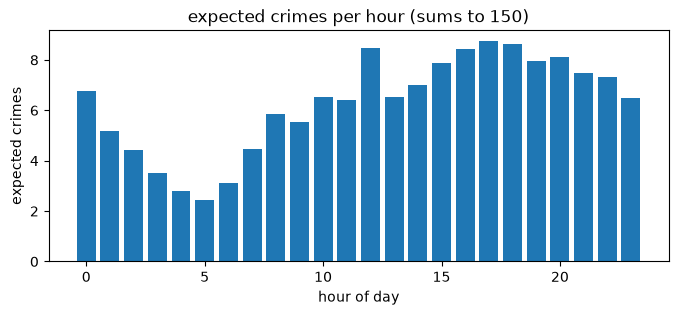

cells clearly above the floor: 251 of 400


In [23]:
hourly = check.sum(axis=(1, 2))
plt.figure(figsize=(8, 3))
plt.bar(range(24), hourly)
plt.xlabel("hour of day")
plt.ylabel("expected crimes")
plt.title("expected crimes per hour (sums to 150)")
plt.show()

cells_above_floor = (check.sum(axis=0) > check.min() * 24 * 1.5).sum()
print("cells clearly above the floor:", int(cells_above_floor), "of 400")